# Neutron Source Demo

In [1]:
from pathlib import Path
import sys
from fusion_fuel_concepts_explorer.sources import SteadyStateSource


## Single DT Example

DT source considering average density and temperature


SteadyStateSource(
  source_type='DT',
  volume_m3=150.0,
  n_i=1e+20,
  T_i=14.0,
  tau_p=1.0,
  tau_p_D=None,
  tau_p_T=None,
  tau_p_He3=None,
  tau_p_He4=None,
  density_fraction_input_by_species={'D': None, 'T': None, 'He3': None, 'He4': None, 'imp': None},
  resolved_density_fraction_by_species={'D': 0.5, 'T': 0.5, 'He3': 0.0, 'He4': 0.0, 'imp': 0.0},
  f_imp=0.0,
  solver_tol=1e-10,
  solver_maxfev=500,
  f_D=0.49698964859154254,
  f_T=0.49703892180715364,
  f_He3=1.583908616641924e-05,
  f_He4=0.005955590515137292,
  f_imp=0.0,
  average_density_m3=1e+20,
  average_temperature_keV=14.0,
)

Average density [m^-3]: 1e+20
Average temperature [keV]: 14
Total fusion power [W]: 2.51818e+08
Neutron energies [eV]: [14100000.  2450000.  3770000.  4030000.]
neutron emission probabilities: [9.92812313e-01 2.64657892e-03 4.54110483e-03 3.57213723e-09]


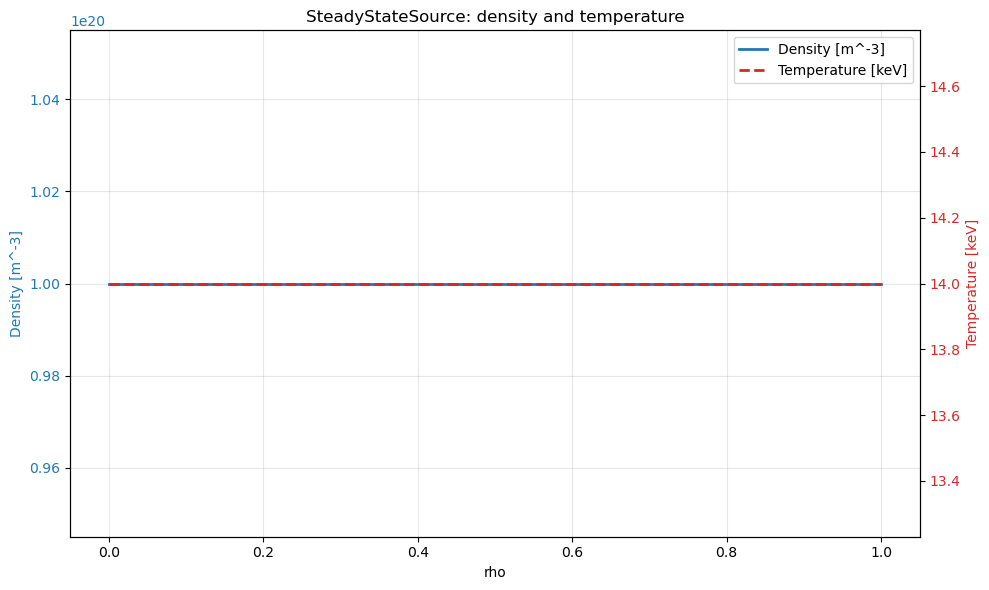

In [2]:
solver = SteadyStateSource(
    source_type="DT",
    volume_m3=150.0,
    n_i=1e20,
    T_i=14.0,
    tau_p=1.0,
)

print(solver)
print(f"\nAverage density [m^-3]: {solver.average_density_m3:.6g}")
print(f"Average temperature [keV]: {solver.average_temperature_keV:.6g}")
print(f"Total fusion power [W]: {solver.total_fusion_power_W:.6g}")

# print OpenMC neutron energies [eV] and emission probabilities for [DT, DDn, TT, THe3n]
print(f"Neutron energies [eV]: {solver.neutron_energies_eV}")
print(f"neutron emission probabilities: {solver.neutron_emission_probabilities}")

fig, ax = solver.plot() # plots density and temperature over normalized radius



SteadyStateSource(
  source_type='DHe3',
  volume_m3=150.0,
  n_i=<function <lambda> at 0x7faf6985aac0>,
  T_i=<function <lambda> at 0x7faf6985ab60>,
  tau_p=1.0,
  tau_p_D=None,
  tau_p_T=None,
  tau_p_He3=None,
  tau_p_He4=None,
  density_fraction_input_by_species={'D': None, 'T': None, 'He3': None, 'He4': None, 'imp': None},
  resolved_density_fraction_by_species={'D': 0.5, 'T': 0.0, 'He3': 0.5, 'He4': 0.0, 'imp': 0.0},
  f_imp=0.0,
  solver_tol=1e-10,
  solver_maxfev=500,
  f_D=0.4951238559601965,
  f_T=0.0004124976662016915,
  f_He3=0.4976732861185959,
  f_He4=0.0067903602550059275,
  f_imp=0.0,
  average_density_m3=2.2052159195212005e+20,
  average_temperature_keV=71.41857176190003,
)
Neutron energies [eV]: [14100000.  2450000.  3770000.  4030000.]
neutron emission probabilities: [7.36579343e-02 9.25998316e-01 1.50013618e-06 3.42249377e-04]


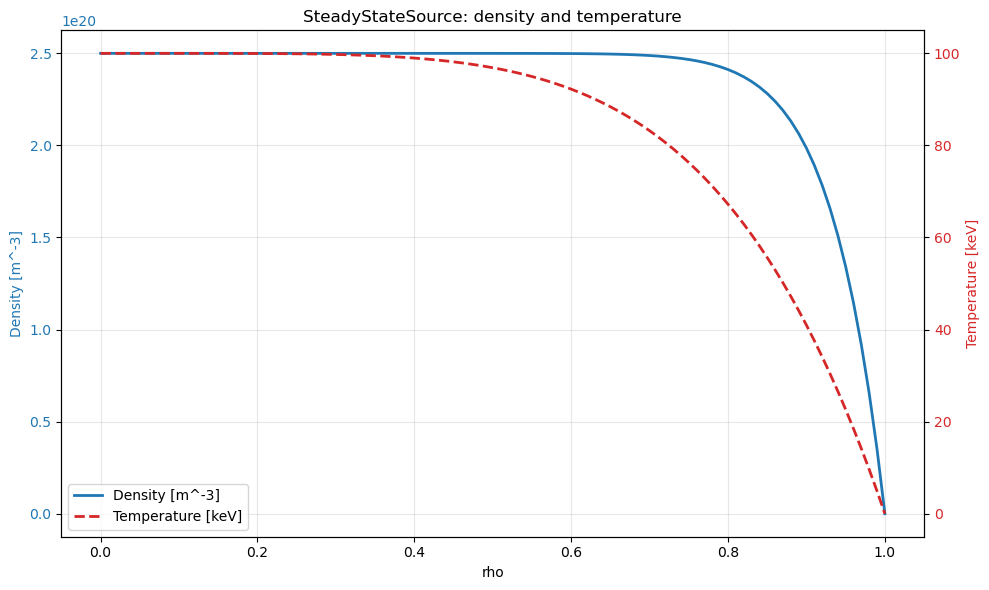

In [3]:
# try density and temperature profiles
max_density = 2.5e20
max_temperature = 100.0
density_profile = lambda r: max_density * (1 - (r / 1.0) ** 15)
temperature_profile = lambda r: max_temperature * (1 - (r / 1.0) ** 5)

solver = SteadyStateSource(
    source_type="DHe3",
    volume_m3=150.0,
    n_i=density_profile,
    T_i=temperature_profile,
    tau_p=1.0,
)
print(solver)

# print OpenMC neutron energies [eV] and emission probabilities for [DT, DDn, TT, THe3n]
print(f"Neutron energies [eV]: {solver.neutron_energies_eV}")
print(f"neutron emission probabilities: {solver.neutron_emission_probabilities}")

fig, ax = solver.plot()